In [1]:
import matplotlib.pyplot as plt
import scipy.constants as c
import numpy as np
from utils import DoubleWellPotential, RingPolymerLangevin

kb = c.k
hbar = c.hbar


def run_simulation(
    n_steps: int = 50000,
    P: int = 32,
    gamma: float = None,
    alpha: float = 1 / 100,
    xc: float = None,
    C: float = 0.8,
    a: float = 0.04e-9,
    seed: int = 42,
):
    """Initialise le potentiel, configure la simulation et exécute la trajectoire."""
    mass = c.m_p
    V0 = hbar**2 / (2.0 * mass * a**2 * C)
    pot = DoubleWellPotential(V0, a)
    T = 0.2 * pot.V0 / kb

    print(f"--- Configuration ---")
    print(f"V0 = {pot.V0:.2e} J ({pot.V0 / c.e:.2f} eV) | T = {T:.2f} K")
    print(f"P = {P} | n_steps = {n_steps} | alpha = {alpha}")

    sim = RingPolymerLangevin(
        potential=pot,
        mass=mass,
        T=T,
        P=P,
        xc=xc,
        gamma=gamma,
        alpha=alpha,
        seed=seed,
    )
    print(f"dt = {sim.dt:.3e} s | gamma = {sim.gamma:.3e} s^-1")

    # Exécution de la dynamique
    res = sim.run(n_steps)
    print("Simulation terminée avec succès.")

    return sim, res

### 1 - Verification du modele (P=1, gamma=0)

In [2]:
# --- Paramètres modifiables ---
N_STEPS = 30000
P_VAL = 1           # Nombre de billes (Trotter number)
GAMMA_VAL = 0     # None pour valeur par défaut (0.1 w_p / 2pi), ou 0.0 pour NVE
ALPHA_VAL = 1 / 100  # Fraction de période pour le pas dt
XC_VAL = None        # Position fixée du centroïde (m), ou None si libre
SEED = None

# Lancement
sim, res = run_simulation(
    n_steps=N_STEPS,
    P=P_VAL,
    gamma=GAMMA_VAL,
    alpha=ALPHA_VAL,
    xc=XC_VAL,
    seed=SEED,
)

--- Configuration ---
V0 = 2.60e-21 J (0.02 eV) | T = 37.62 K
P = 1 | n_steps = 30000 | alpha = 0.01
dt = 1.008e-15 s | gamma = 0.000e+00 s^-1
Simulation terminée avec succès.


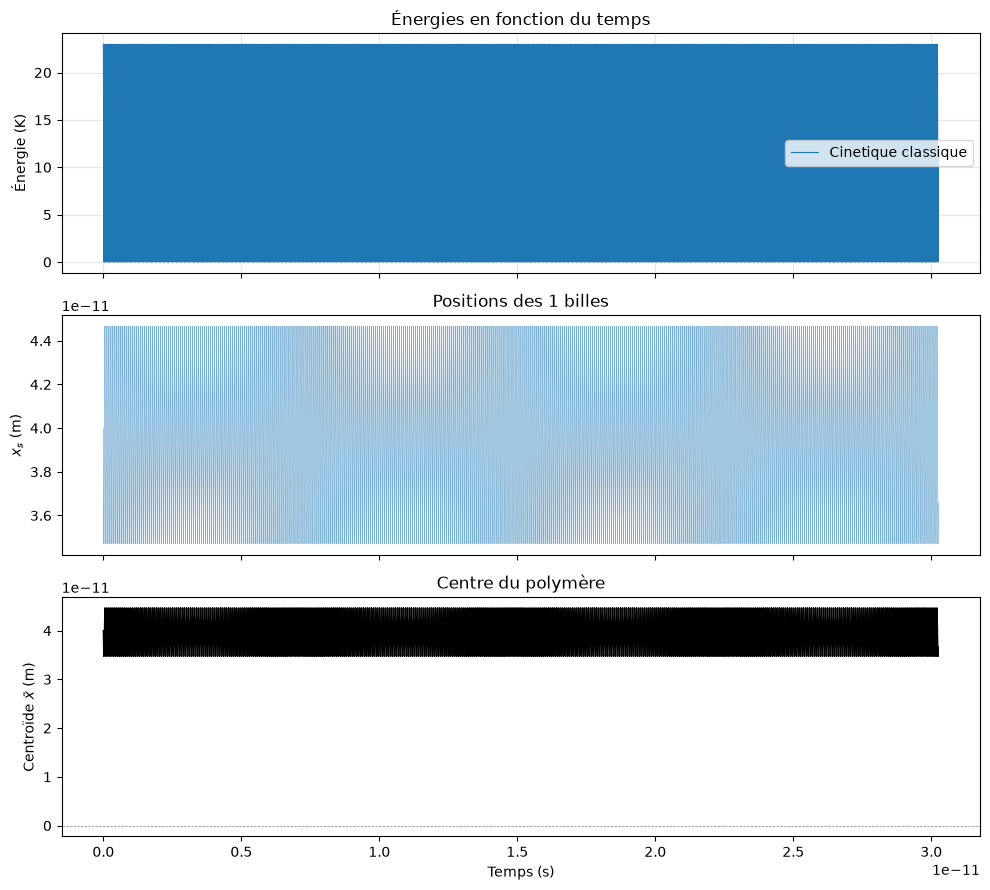

In [4]:

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(res.t, res.e_kin_class_kelvin, label="Cinetique classique", lw=0.8)
axes[0].set_ylabel("Énergie (K)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Énergies en fonction du temps")

axes[1].plot(res.t, res.X, lw=0.5, alpha=0.6)
axes[1].set_ylabel("$x_s$ (m)")
axes[1].set_title(f"Positions des {res.P} billes")

axes[2].plot(res.t, res.centroid, color="k", lw=1)
axes[2].axhline(0, color="gray", ls="--", lw=0.5)
axes[2].set_ylabel(r"Centroïde $\bar{x}$ (m)")
axes[2].set_xlabel("Temps (s)")
axes[2].set_title("Centre du polymère")

fig.tight_layout()
plt.show()